# 02 多档补贴出价与离线评估

动作是 0、1、2、4 单位补贴。模拟历史策略偏向给敏感用户更高金额；日志保存动作概率。IPS 与 DR 需要正确的概率、重叠支持和一致的结果定义。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from IPython.display import display
plt.style.use('seaborn-v0_8-whitegrid')
pd.options.display.float_format='{:.3f}'.format
rng=np.random.default_rng(123);n=25000
X=pd.DataFrame({'sensitivity':rng.uniform(size=n),'baseline':rng.uniform(size=n)})
amounts=np.array([0,1,2,4]);p0=.12+.55*X.baseline.to_numpy()
potential=np.column_stack([np.clip(p0+(.22*X.sensitivity.to_numpy()+.04)*(1-np.exp(-a/1.5))-.012*a,.01,.98) for a in amounts])
x=X.sensitivity.to_numpy()
logits=np.column_stack([np.zeros(n),.3+x,.1+2*x,-.4+3*x])
prob=np.exp(logits-logits.max(axis=1,keepdims=True));prob/=prob.sum(axis=1,keepdims=True)
action=np.array([rng.choice(4,p=p) for p in prob])
reward=rng.binomial(1,potential[np.arange(n),action])
df=X.assign(action=action,amount=amounts[action],active=reward,propensity=prob[np.arange(n),action])
display(df.head());print('Minimum propensity:',df.propensity.min())

,sensitivity,baseline,action,amount,active,propensity
0,0.682,0.054,0,0,0,0.076
1,0.054,0.624,3,4,1,0.177
2,0.220,0.013,0,0,0,0.175
3,0.184,0.428,3,4,1,0.216
4,0.176,0.491,2,2,0,0.296


Minimum propensity: 0.03803481567541847


## 选择偏差

按金额观察的活跃率混合了金额效果和人群差异。“总体潜在均值”仅为模拟真值。

,observed,sensitivity,count,population_potential
amount,,,,
0,0.402,0.351,2945,0.395
1,0.454,0.425,6012,0.456
2,0.473,0.507,7725,0.481
4,0.508,0.590,8318,0.486


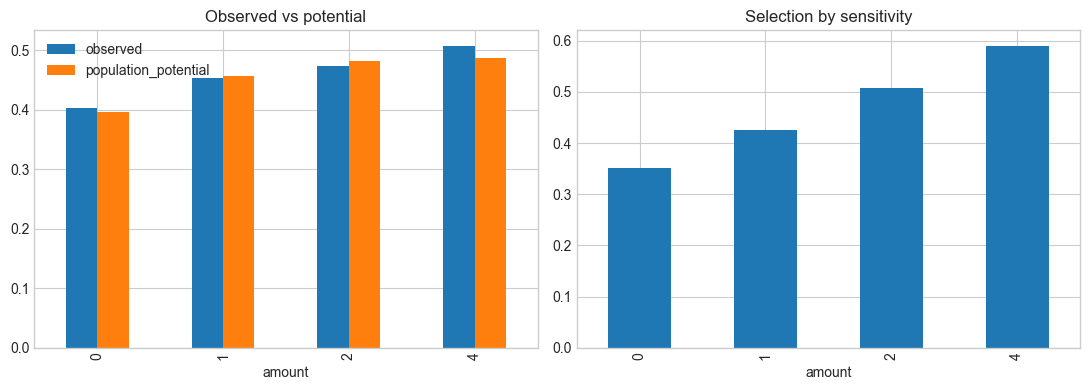

In [2]:
s=df.groupby('amount').agg(observed=('active','mean'),sensitivity=('sensitivity','mean'),count=('active','size'))
s['population_potential']=potential.mean(axis=0)
display(s)
fig,ax=plt.subplots(1,2,figsize=(11,4))
s[['observed','population_potential']].plot.bar(ax=ax[0],title='Observed vs potential')
s.sensitivity.plot.bar(ax=ax[1],title='Selection by sensitivity')
plt.tight_layout();plt.show()

## IPS、DR 与策略

在训练集拟合各动作结果模型，在独立测试日志上评估。候选策略的目标是活跃概率减金额成本；模拟最优策略仅用于校验。

In [3]:
tr,te=train_test_split(np.arange(n),test_size=.4,random_state=8)
models=[]
for a in range(4):
    ix=tr[action[tr]==a]
    models.append(LogisticRegression(max_iter=500).fit(X.iloc[ix],reward[ix]))
mu=np.column_stack([m.predict_proba(X.iloc[te])[:,1] for m in models])
pot=potential[te];ha=action[te];hp=prob[te,ha];r=reward[te]
cost=.025*amounts
policies={'no subsidy':np.zeros(len(te),dtype=int),'always 2':np.full(len(te),2),
          'model net value':np.argmax(mu-cost,axis=1),'oracle (simulation)':np.argmax(pot-cost,axis=1)}
def evaluate(target):
    w=(ha==target)/hp
    ips=np.mean(w*r)
    dr=np.mean(mu[np.arange(len(te)),target]+w*(r-mu[np.arange(len(te)),ha]))
    truth=np.mean(pot[np.arange(len(te)),target])
    return ips,dr,truth,np.mean(amounts[target]),w.sum()**2/(w@w)
table=pd.DataFrame({k:evaluate(v) for k,v in policies.items()},index=['IPS active','DR active','simulated truth','mean amount','IPS effective sample size']).T
display(table)

,IPS active,DR active,simulated truth,mean amount,IPS effective sample size
no subsidy,0.386,0.405,0.397,0.000,877.540
always 2,0.475,0.463,0.482,2.000,3183.641
model net value,0.453,0.456,0.466,1.186,2597.221
oracle (simulation),0.464,0.464,0.474,1.336,2847.217


## 抽样波动和预算曲线

Bootstrap 展示单次离线评估的波动。通过搜索金额的影子价格近似满足人均预算；生产系统还需逐时 pacing。

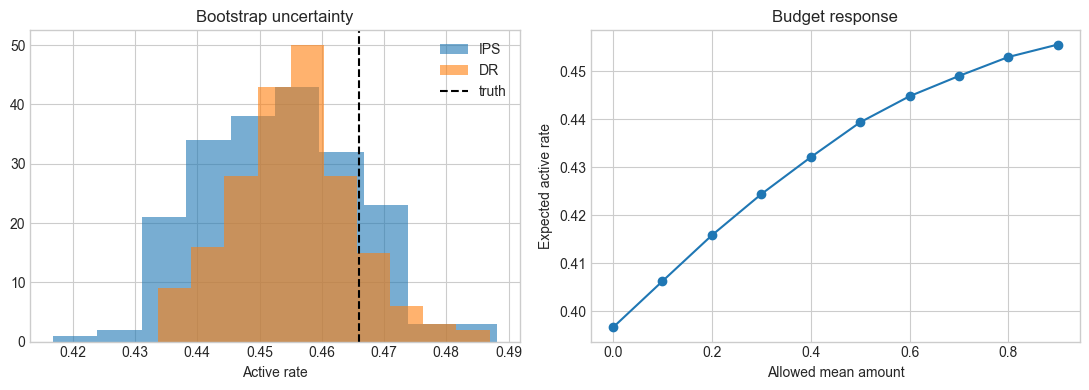

,budget,spend,expected_active
0,0.000,0.000,0.397
1,0.100,0.091,0.406
2,0.200,0.191,0.416
3,0.300,0.292,0.424
4,0.400,0.391,0.432
5,0.500,0.499,0.439
6,0.600,0.596,0.445
7,0.700,0.687,0.449
8,0.800,0.795,0.453
9,0.900,0.898,0.456


In [4]:
target=policies['model net value'];w=(ha==target)/hp
base=mu[np.arange(len(te)),target];correction=w*(r-mu[np.arange(len(te)),ha])
boot=np.array([rng.integers(0,len(te),len(te)) for _ in range(200)])
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].hist(np.mean((w*r)[boot],axis=1),alpha=.6,label='IPS')
ax[0].hist(np.mean((base+correction)[boot],axis=1),alpha=.6,label='DR')
ax[0].axvline(np.mean(pot[np.arange(len(te)),target]),color='black',linestyle='--',label='truth')
ax[0].legend();ax[0].set(title='Bootstrap uncertainty',xlabel='Active rate')
rows=[]
for budget in np.linspace(0,.9,10):
    options=[]
    for price in np.linspace(0,.5,401):
        a=np.argmax(mu-price*amounts,axis=1);spend=np.mean(amounts[a])
        if spend<=budget+1e-9:options.append((np.mean(pot[np.arange(len(te)),a]),spend))
    value,spend=max(options);rows.append((budget,spend,value))
curve=pd.DataFrame(rows,columns=['budget','spend','expected_active'])
ax[1].plot(curve.budget,curve.expected_active,marker='o')
ax[1].set(title='Budget response',xlabel='Allowed mean amount',ylabel='Expected active rate')
plt.tight_layout();plt.show();display(curve)

## 结论与真实数据接口

历史策略与人群相关时，直接按金额比较会误导。IPS/DR 仍可能因 propensity 错误、缺乏重叠、延迟结果或未观测混杂而失效。真实日志至少需要候选动作集、动作选择概率、处理前特征、实际金额、结果和时间戳。生成式模型可产生候选金额，最终应经过预算、频控和体验约束筛选，再用随机实验验证。